# Correlation Analysis: Marketing Dataset (Python)

Python version of the R analysis in this repo, extended with a second question.

**Research questions**
1. Is there an association between a customer's annual household income and total spending over the last two years?
2. Do households with children spend less on alcohol (wine), and does this hold once income is taken into account?

**Source:** Kaggle, *Customer Personality Analysis* (2,240 customers)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
SEED = 42

## 1. Load data and derive variables

In [2]:
df = pd.read_csv("marketing_data.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()
df["Income"] = pd.to_numeric(df["Income"].astype(str).str.replace(r"[$,\s]", "", regex=True), errors="coerce")

mnt = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["TotalSpend"] = df[mnt].sum(axis=1)
df["Children"] = df["Kidhome"] + df["Teenhome"]
df["Age"] = 2025 - df["Year_Birth"]
print(df.shape)

(2240, 31)


### Visual check before cleaning

Boxplots of the raw income and spending values, to spot values that do not fit.

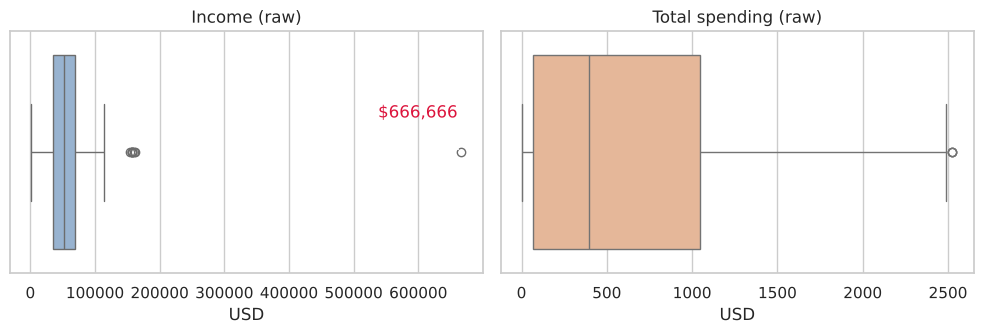

Two highest incomes: [666666.0, 162397.0]
Oldest birth years: [1893, 1899, 1900, 1940]


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=df["Income"], ax=axes[0], color="#8fb3d9")
axes[0].set(title="Income (raw)", xlabel="USD")
sns.boxplot(x=df["TotalSpend"], ax=axes[1], color="#f2b48c")
axes[1].set(title="Total spending (raw)", xlabel="USD")
top = df["Income"].nlargest(2)
axes[0].annotate(f"${top.iloc[0]:,.0f}", (top.iloc[0], 0), xytext=(-60, 25), textcoords="offset points",
                 arrowprops=dict(arrowstyle="->"), color="crimson")
plt.tight_layout()
plt.show()
print("Two highest incomes:", top.tolist())
print("Oldest birth years:", sorted(df["Year_Birth"])[:4])

## 2. Data cleaning

Same rules as the R version: the $666,666 income entry is a data entry error, and birth years before 1930 are biologically implausible.

In [4]:
n_before = len(df)
df = df[~(df["Income"] == 666666)]
df = df[df["Year_Birth"] >= 1930].copy()
print(f"Removed {n_before - len(df)} rows: {n_before} -> {len(df)}")
print("Missing Income:", df["Income"].isna().sum())

Removed 4 rows: 2240 -> 2236
Missing Income: 24


## 3. Random Forest imputation of missing income

In [5]:
predictors = ["Education", "Age", "TotalSpend", "Kidhome", "Teenhome",
              "NumCatalogPurchases", "NumStorePurchases"]
X_all = pd.get_dummies(df[predictors], columns=["Education"], drop_first=True)

known = df["Income"].notna()
X_tr, X_te, y_tr, y_te = train_test_split(X_all[known], df.loc[known, "Income"],
                                          test_size=0.2, random_state=SEED)
rf = RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
pred = rf.predict(X_te)
print(f"Hold-out R^2: {r2_score(y_te, pred):.3f} | MAE: ${mean_absolute_error(y_te, pred):,.0f}")

rf_full = RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1).fit(X_all[known], df.loc[known, "Income"])
df["Income_imp"] = df["Income"]
df.loc[~known, "Income_imp"] = rf_full.predict(X_all[~known])

Hold-out R^2: 0.741 | MAE: $7,127


## 4. Income vs total spending

In [6]:
x, y = df["Income_imp"], df["TotalSpend"]
pear = stats.pearsonr(x, y)
logp = stats.pearsonr(np.log(x), np.log1p(y))
spear = stats.spearmanr(x, y)
pd.DataFrame({
    "Method": ["Pearson", "Log-Pearson", "Spearman"],
    "Coefficient": [pear[0], logp[0], spear[0]],
    "p-value": [pear[1], logp[1], spear[1]],
}).round(4)

,Method,Coefficient,p-value
0,Pearson,0.7937,0.0
1,Log-Pearson,0.7588,0.0
2,Spearman,0.8536,0.0


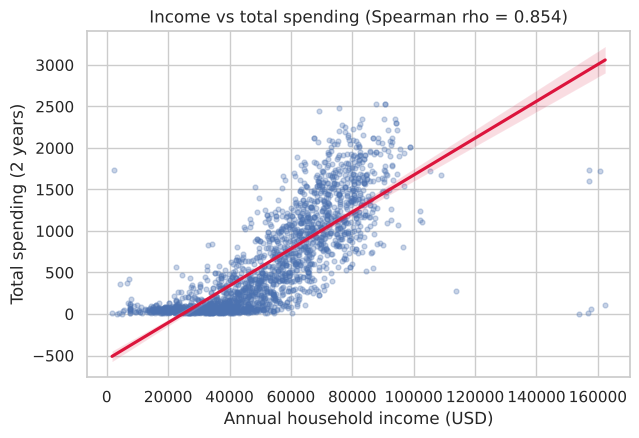

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.regplot(x=x, y=y, scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "crimson"}, ax=ax)
ax.set(xlabel="Annual household income (USD)", ylabel="Total spending (2 years)",
       title=f"Income vs total spending (Spearman rho = {spear[0]:.3f})")
plt.show()

In [8]:
rows = [(m, *stats.spearmanr(df["Income_imp"], df[m])) for m in mnt]
pd.DataFrame(rows, columns=["Category", "Spearman rho", "p-value"]).sort_values("Spearman rho", ascending=False).round(4)

,Category,Spearman rho,p-value
0,MntWines,0.8319,0.0
2,MntMeatProducts,0.8186,0.0
1,MntFruits,0.5817,0.0
3,MntFishProducts,0.5789,0.0
4,MntSweetProducts,0.5682,0.0
5,MntGoldProds,0.5071,0.0


## 5. Children and alcohol (wine) spending

First the raw association, then a **partial Spearman correlation** that removes the effect of income from both variables. If the link shrinks a lot, income is a confounder.

In [9]:
raw = stats.spearmanr(df["Children"], df["MntWines"])
inc_child = stats.spearmanr(df["Income_imp"], df["Children"])

def partial_spearman(data, a, b, control):
    r = data[[a, b, control]].rank()
    def resid(col):
        X = np.c_[np.ones(len(r)), r[control]]
        beta = np.linalg.lstsq(X, r[col], rcond=None)[0]
        return r[col] - X @ beta
    return stats.pearsonr(resid(a), resid(b))

part = partial_spearman(df, "Children", "MntWines", "Income_imp")
pd.DataFrame({
    "Relationship": ["Children vs Wine (raw)", "Income vs Children", "Children vs Wine | Income (partial)"],
    "Spearman rho": [raw[0], inc_child[0], part[0]],
    "p-value": [raw[1], inc_child[1], part[1]],
}).round(4)

,Relationship,Spearman rho,p-value
0,Children vs Wine (raw),-0.3350,0.000
1,Income vs Children,-0.3746,0.000
2,Children vs Wine | Income (partial),-0.0454,0.032


In [10]:
summary = df.assign(HasChildren=np.where(df["Children"] > 0, "With children", "No children")) \
    .groupby("HasChildren").agg(
        Customers=("ID", "count"),
        Median_income=("Income_imp", "median"),
        Median_wine=("MntWines", "median"),
        Wine_share_of_spend=("MntWines", "sum"),
        Total=("TotalSpend", "sum"))
summary["Wine_share_of_spend"] = (summary["Wine_share_of_spend"] / summary.pop("Total")).round(3)
summary.round({"Median_income": 0, "Median_wine": 0, "Wine_share_of_spend": 3})

,Customers,Median_income,Median_wine,Wine_share_of_spend
HasChildren,,,,
No children,637,72190.0,450.0,0.441
With children,1599,45894.0,93.0,0.568


Kidhome vs Wine : -0.581
Teenhome vs Wine: 0.112


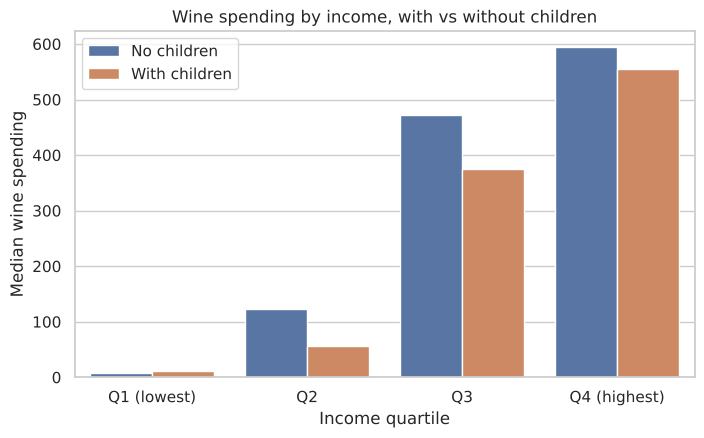

In [11]:
print("Kidhome vs Wine :", round(stats.spearmanr(df["Kidhome"], df["MntWines"])[0], 3))
print("Teenhome vs Wine:", round(stats.spearmanr(df["Teenhome"], df["MntWines"])[0], 3))

df["IncomeQuartile"] = pd.qcut(df["Income_imp"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df, x="IncomeQuartile", y="MntWines", hue=(df["Children"] > 0).map({True: "With children", False: "No children"}),
            estimator=np.median, errorbar=None, ax=ax)
ax.set(xlabel="Income quartile", ylabel="Median wine spending", title="Wine spending by income, with vs without children")
ax.legend(title="")
plt.show()

## 6. Correlation heatmap

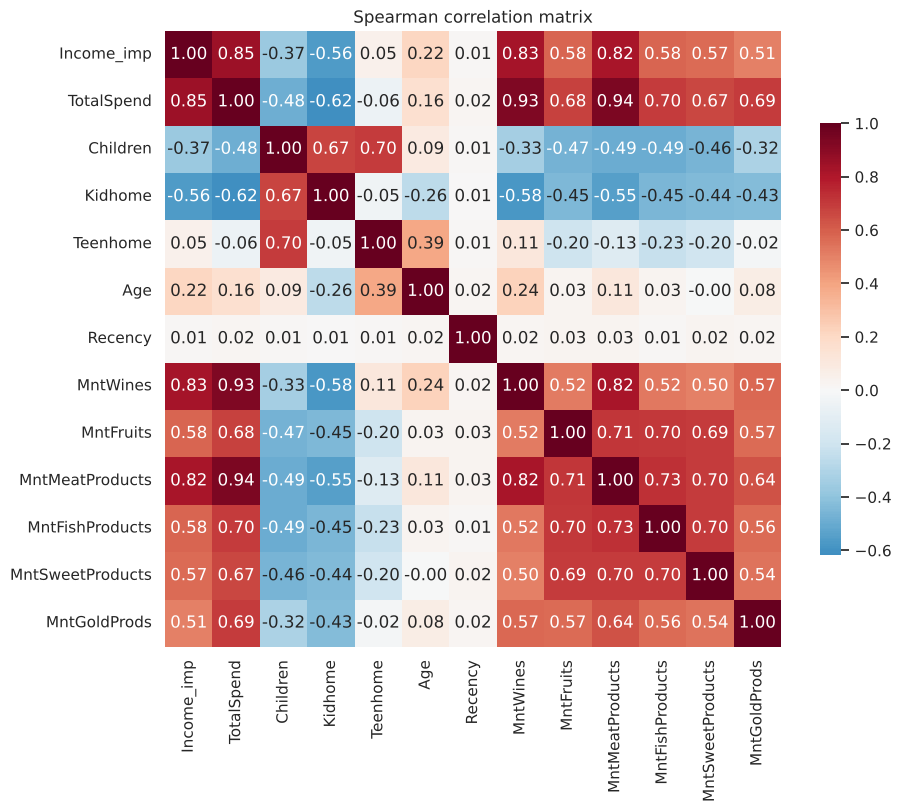

In [12]:
cols = ["Income_imp", "TotalSpend", "Children", "Kidhome", "Teenhome", "Age", "Recency"] + mnt
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.show()

## 7. Key findings

- Strong positive association between income and total spending (Spearman, see section 4); wine and meat are the categories most tied to income.
- Households with more children spend clearly less on wine, but they also earn less. After controlling for income, the children and wine link nearly disappears, so income is the main driver.
- Young children (Kidhome) are associated with lower wine spending, while teenagers (Teenhome) show a slightly positive association.